In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Fill missing TotalCharges
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Remove duplicate rows, if any
df = df.drop_duplicates().copy()

# Remove customer ID because it is an identifier
df = df.drop(columns=["customerID"])

# Convert target labels to 0 and 1
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Data cleaning completed!")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
display(df.head())

Data cleaning completed!
Shape: (7043, 20)
Missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [4]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target percentages:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5634
Testing records: 1409


In [6]:
numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\HP\AppData\Local\Temp\ipykernel_16096\3002084416.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [7]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [8]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [9]:
# Predict customer churn
y_pred = lr_model.predict(X_test)

# Probability of churn (class 1)
y_proba = lr_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("Logistic Regression Results")
print("-" * 35)

print("Accuracy: ", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:   ", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score: ", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

Logistic Regression Results
-----------------------------------
Accuracy:  0.8055
Precision: 0.6572
Recall:    0.5588
F1 Score:  0.604
ROC-AUC:   0.8421

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



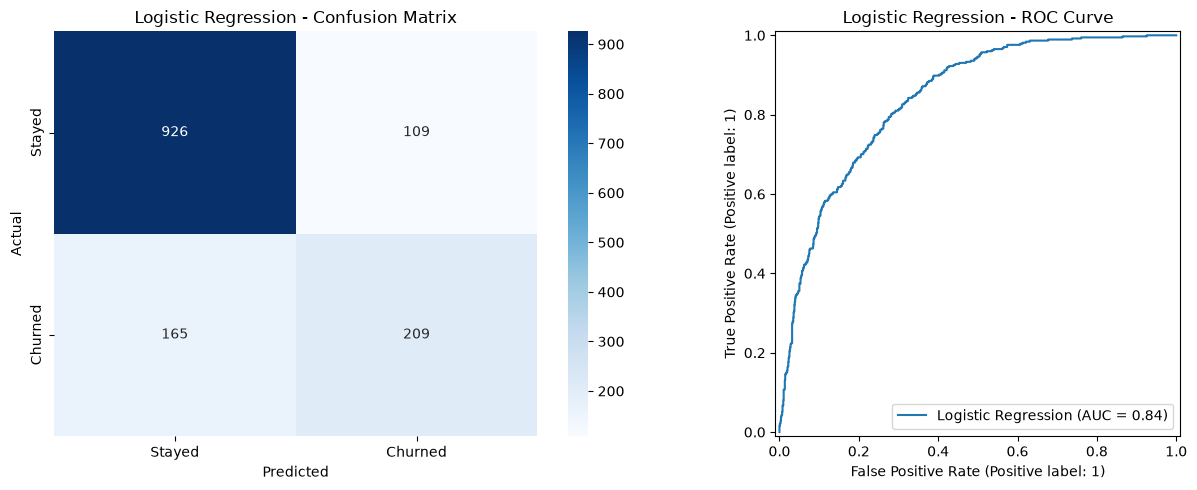

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression - Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    ax=axes[1],
    name="Logistic Regression"
)

axes[1].set_title("Logistic Regression - ROC Curve")

plt.tight_layout()
plt.show()

In [11]:
#Train Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [12]:
#Make Predictions 
y_pred_rf = rf_model.predict(X_test)

y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:", y_pred_rf[:10])
print("First 10 churn probabilities:", y_proba_rf[:10].round(3))

First 10 predictions: [0 1 0 0 0 1 1 0 0 1]
First 10 churn probabilities: [0.013 0.818 0.107 0.491 0.055 0.784 0.533 0.185 0.009 0.573]


In [13]:
#Evaluate Random Forest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("RANDOM FOREST RESULTS")
print("-" * 35)

print("Accuracy: ", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1 Score: ", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_proba_rf), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

RANDOM FOREST RESULTS
-----------------------------------
Accuracy:  0.7594
Precision: 0.5336
Recall:    0.7433
F1 Score:  0.6212
ROC-AUC:   0.8362

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.89      0.77      0.82      1035
     Churned       0.53      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



In [14]:
#Compare Both Models Logistic Regression vs Random Forest
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_model.predict(X_test)),
        "Precision": precision_score(
            y_test, lr_model.predict(X_test), zero_division=0
        ),
        "Recall": recall_score(
            y_test, lr_model.predict(X_test), zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, lr_model.predict(X_test), zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, lr_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(
            y_test, y_pred_rf, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_rf, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred_rf, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_proba_rf)
    }
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest,0.7594,0.5336,0.7433,0.6212,0.8362


In [15]:
from xgboost import XGBClassifier

print("XGBoost Library imported successfully!")

XGBoost Library imported successfully!


In [16]:
#Train XGBoost Model

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [17]:
#Make Predictions 
y_pred_xgb = xgb_model.predict(X_test)

y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:", y_pred_xgb[:10])
print("First 10 churn probabilities:", y_proba_xgb[:10].round(3))

First 10 predictions: [0 1 0 0 0 1 1 0 0 0]
First 10 churn probabilities: [0.01  0.906 0.081 0.314 0.007 0.689 0.536 0.104 0.011 0.402]


In [18]:
#Evaluate XGBoost Model
print("XGBOOST RESULTS")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 4))
print("Precision:", round(precision_score(y_test, y_pred_xgb, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_xgb, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_xgb, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_xgb), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

XGBOOST RESULTS
-----------------------------------
Accuracy: 0.7991
Precision: 0.6522
Recall: 0.5214
F1 Score: 0.5795
ROC-AUC: 0.8426

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.84      0.90      0.87      1035
     Churned       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [19]:
#Compare all three models: Logistic Regression, Random Forest, and XGBoost
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

comparison = []

for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

results = pd.DataFrame(comparison)

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest,0.7594,0.5336,0.7433,0.6212,0.8362
2,XGBoost,0.7991,0.6522,0.5214,0.5795,0.8426


In [20]:
#Sort the results by ROC-AUC in increasing order
display(
    results.sort_values("ROC-AUC", ascending=False)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.7991,0.6522,0.5214,0.5795,0.8426
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Random Forest,0.7594,0.5336,0.7433,0.6212,0.8362


In [21]:
from sklearn.metrics import classification_report, confusion_matrix

# Get churn probabilities from Random Forest
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Try a lower threshold
threshold = 0.40
y_pred_rf_tuned = (y_proba_rf >= threshold).astype(int)

print("Threshold:", threshold)
print(classification_report(
    y_test,
    y_pred_rf_tuned,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

Threshold: 0.4
              precision    recall  f1-score   support

      Stayed       0.92      0.70      0.79      1035
     Churned       0.50      0.83      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.81      0.73      0.75      1409

Confusion Matrix:
[[721 314]
 [ 63 311]]


In [22]:
import os
import joblib

# Create the models folder in the project root
os.makedirs("../models", exist_ok=True)

# Save the complete Random Forest pipeline
joblib.dump(
    rf_model,
    "../models/customer_churn_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [23]:
import joblib

# Load the saved model
loaded_model = joblib.load(
    "../models/customer_churn_model.pkl"
)

# Select one customer from the test set
sample_customer = X_test.iloc[[0]]

# Make prediction
prediction = loaded_model.predict(sample_customer)[0]
probability = loaded_model.predict_proba(sample_customer)[0][1]

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print(f"Churn probability: {probability:.2%}")

Prediction: No Churn
Churn probability: 1.34%


In [24]:
import joblib
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model = joblib.load("../models/customer_churn_model.pkl")

# Predict using the saved pipeline
y_pred_saved = model.predict(X_test)
y_prob_saved = model.predict_proba(X_test)[:, 1]

# Validate predictions
assert np.isfinite(y_prob_saved).all()
assert ((y_prob_saved >= 0) & (y_prob_saved <= 1)).all()

print("Saved model loaded successfully!")
print("Accuracy:", round(accuracy_score(y_test, y_pred_saved), 4))
print("Precision:", round(precision_score(y_test, y_pred_saved, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_saved, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_saved, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_saved), 4))

Saved model loaded successfully!
Accuracy: 0.7594
Precision: 0.5336
Recall: 0.7433
F1-score: 0.6212
ROC-AUC: 0.8362
